# Traffic: the Nagel–Schreckenberg model

Cars on a single-lane ring road of 200 cells. Each step, every car does four things. (1) It accelerates by 1, up to v_max = 5. (2) It brakes to the gap to the car ahead. (3) With probability p it slows by 1 at random. (4) It moves. All cars update together. Slides 20–23.

*Made for this site, following the rules on the slides (`1 Lecture/Agent Based Modelling with Mesa - Slides.html`). It uses Mesa 3 (`mesa.discrete_space`), tested with Mesa 3.5.1 in the browser. The interactive Solara versions on py.cafe, linked from the slides, need the internet and run outside this site.*

In [ ]:
# Run this cell first.
# In the browser (JupyterLite) it installs the extra packages into this tab;
# in Colab or Anaconda it installs them with pip (already installed = no change).
%pip install mesa networkx

In [2]:
import mesa
import numpy as np
import matplotlib.pyplot as plt

**The model.** d_i = the number of empty cells in front of car i.

In [3]:
class Car(mesa.Agent):
    def __init__(self, model, x):
        super().__init__(model)
        self.x = x
        self.v = 0

    def plan(self):
        m = self.model
        gap = (m.ahead[self] - self.x - 1) % m.length
        self.v = min(self.v + 1, m.v_max)            # 1. accelerate
        self.v = min(self.v, gap)                    # 2. brake to the gap
        if self.v > 0 and self.random.random() < m.p:
            self.v -= 1                              # 3. random slow-down

    def move(self):
        self.x = (self.x + self.v) % self.model.length   # 4. move


class NaSch(mesa.Model):
    def __init__(self, length=200, density=0.2, v_max=5, p=0.3, seed=1):
        super().__init__(rng=seed)
        self.length, self.v_max, self.p = length, v_max, p
        for x in sorted(self.random.sample(range(length), int(density * length))):
            Car(self, x)

    def step(self):
        cars = sorted(self.agents, key=lambda c: c.x)
        self.ahead = {c: cars[(k + 1) % len(cars)].x for k, c in enumerate(cars)}
        self.agents.do("plan")
        self.agents.do("move")

    def road(self):
        r = np.full(self.length, np.nan)
        for c in self.agents:
            r[c.x] = c.v
        return r

**Space–time diagram.** Each row is one step and each dot is a car, coloured by speed. Predict first: will jams appear without any cause such as an accident? Which way do they move?

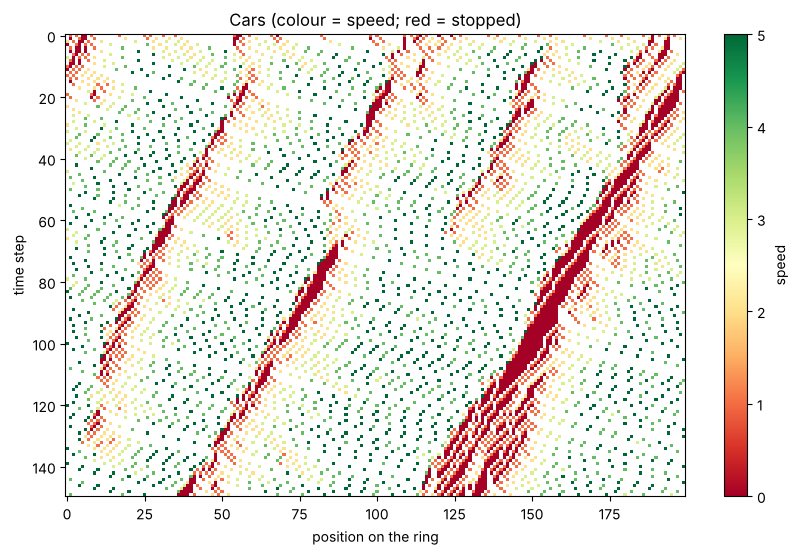

In [4]:
model = NaSch()
rows = []
for _ in range(150):
    model.step(); rows.append(model.road())
fig, ax = plt.subplots(figsize=(10, 6))
im = ax.imshow(np.array(rows), aspect="auto", cmap="RdYlGn", interpolation="nearest", vmin=0, vmax=5)
ax.set(xlabel="position on the ring", ylabel="time step", title="Cars (colour = speed; red = stopped)")
fig.colorbar(im, label="speed"); plt.show()

**Fundamental diagram.** Traffic flow (cars passing a point per step = density × mean speed) against density. Free flow rises with density, then congestion sets in.

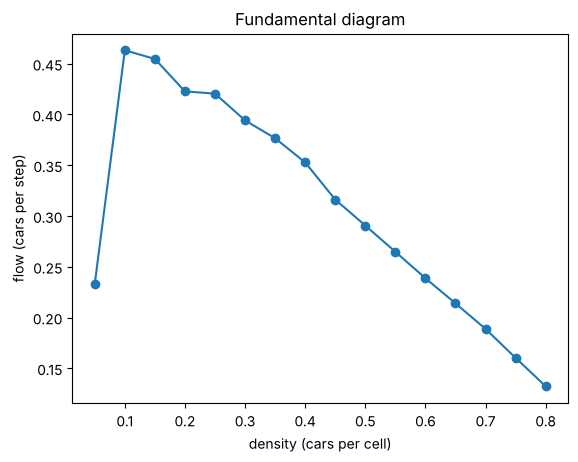

Highest flow 0.463 at density 0.10


In [5]:
densities = np.arange(0.05, 0.85, 0.05)
flow = []
for d in densities:
    m = NaSch(density=d, seed=2)
    for _ in range(100):
        m.step()                                   # warm-up
    speeds = []
    for _ in range(100):
        m.step(); speeds.append(np.mean([c.v for c in m.agents]))
    flow.append(d * np.mean(speeds))
plt.plot(densities, flow, marker="o"); plt.xlabel("density (cars per cell)"); plt.ylabel("flow (cars per step)")
plt.title("Fundamental diagram"); plt.show()
print(f"Highest flow {max(flow):.3f} at density {densities[int(np.argmax(flow))]:.2f}")